In [64]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy import stats

In [65]:
import pandas as pd

# Path is relative to the repository root when the notebook is run from notebooks/
DATA_PATH = "../data/Health_Sleep_Statistics.csv"
df = pd.read_csv(DATA_PATH)

In [66]:
print("=== Dataset Shape ===")
print(df.shape)
print("\n=== Basic Info ===")
print(df.info())


=== Dataset Shape ===
(100, 12)

=== Basic Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   User ID                  100 non-null    int64 
 1   Age                      100 non-null    int64 
 2   Gender                   100 non-null    object
 3   Sleep Quality            100 non-null    int64 
 4   Bedtime                  100 non-null    object
 5   Wake-up Time             100 non-null    object
 6   Daily Steps              100 non-null    int64 
 7   Calories Burned          100 non-null    int64 
 8   Physical Activity Level  100 non-null    object
 9   Dietary Habits           100 non-null    object
 10  Sleep Disorders          100 non-null    object
 11  Medication Usage         100 non-null    object
dtypes: int64(5), object(7)
memory usage: 9.5+ KB
None


In [67]:
print("\n=== Summary Statistics ===")
print(df.describe())
print("\n=== Missing Values ===")
print(df.isna().sum())



=== Summary Statistics ===
          User ID         Age  Sleep Quality   Daily Steps  Calories Burned
count  100.000000  100.000000     100.000000    100.000000        100.00000
mean    50.500000   36.010000       7.000000   6830.000000       2421.00000
std     29.011492    8.454865       1.734964   2498.706736        281.06759
min      1.000000   22.000000       4.000000   3000.000000       2000.00000
25%     25.750000   28.750000       5.750000   4750.000000       2175.00000
50%     50.500000   35.000000       7.500000   6750.000000       2400.00000
75%     75.250000   44.000000       8.250000   9000.000000       2700.00000
max    100.000000   50.000000       9.000000  11000.000000       2900.00000

=== Missing Values ===
User ID                    0
Age                        0
Gender                     0
Sleep Quality              0
Bedtime                    0
Wake-up Time               0
Daily Steps                0
Calories Burned            0
Physical Activity Level    0
Die

In [68]:
print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())
print("\n=== Columns ===")
print(df.columns)


=== Duplicate Rows ===
0

=== Columns ===
Index(['User ID', 'Age', 'Gender', 'Sleep Quality', 'Bedtime', 'Wake-up Time',
       'Daily Steps', 'Calories Burned', 'Physical Activity Level',
       'Dietary Habits', 'Sleep Disorders', 'Medication Usage'],
      dtype='object')


In [69]:
age_vs_sleep_quality_corr = df[['Age', 'Sleep Quality']].corr()
print("\n=== Correlation: Age vs Sleep Quality ===")
print(age_vs_sleep_quality_corr)


=== Correlation: Age vs Sleep Quality ===
                    Age  Sleep Quality
Age            1.000000      -0.848356
Sleep Quality -0.848356       1.000000


In [70]:

relation_coeff = age_vs_sleep_quality_corr.iloc[0, 1]
print(f"Correlation Coefficient: {relation_coeff:.3f}")

Correlation Coefficient: -0.848


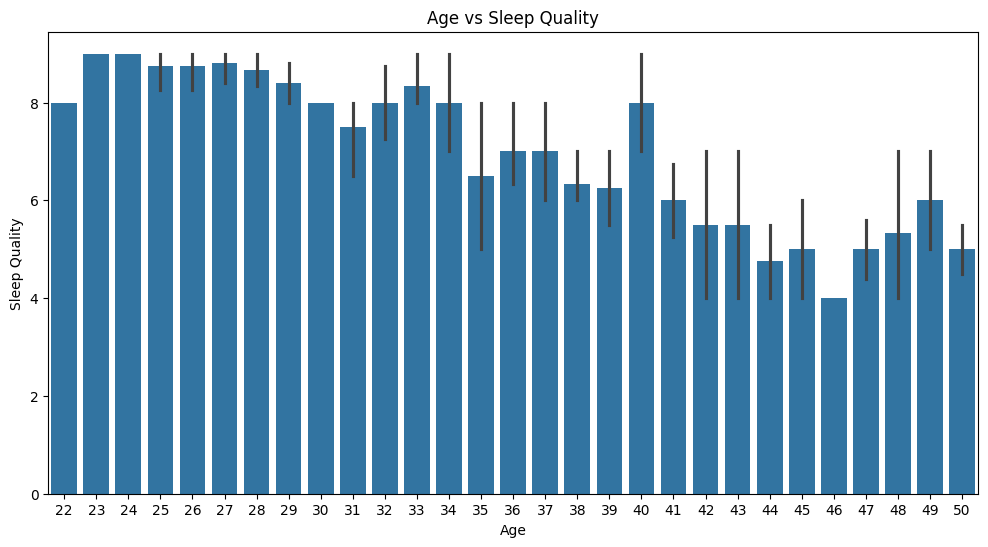

In [71]:
plt.figure(figsize=(12,6))
sns.barplot(x='Age', y='Sleep Quality', data=df)
plt.title("Age vs Sleep Quality")
plt.xlabel("Age")
plt.ylabel("Sleep Quality")
plt.show()

In [72]:
X = df[['Age']]
Y = df['Sleep Quality']
model = LinearRegression()
model.fit(X, Y)

LinearRegression()

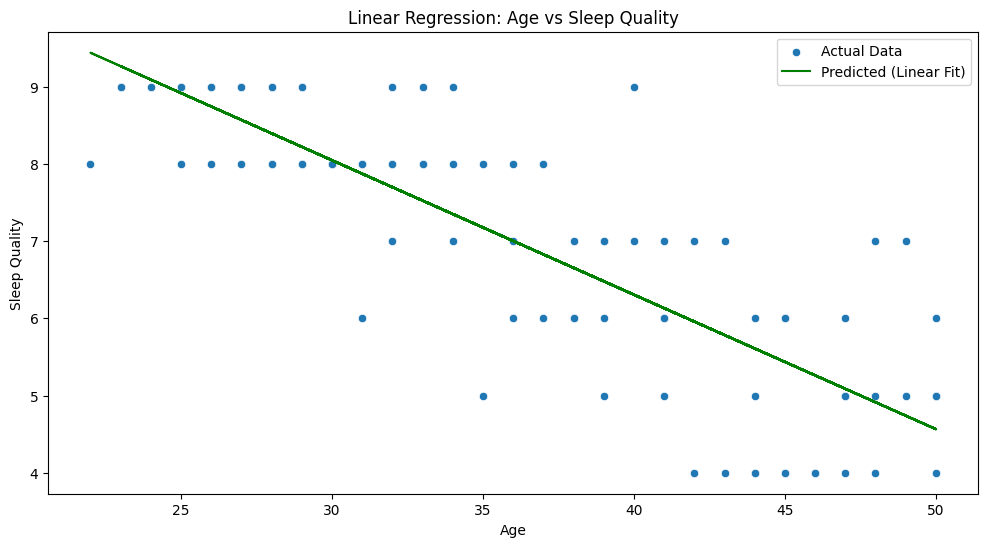

Model Coefficient: [-0.17408531]
Model Intercept: 13.268812023190646


In [73]:
plt.figure(figsize=(12,6))
sns.scatterplot(x='Age', y='Sleep Quality', data=df, label='Actual Data')
plt.plot(X, model.predict(X), color='green', label='Predicted (Linear Fit)')
plt.title("Linear Regression: Age vs Sleep Quality")
plt.legend()
plt.show()

print("Model Coefficient:", model.coef_)
print("Model Intercept:", model.intercept_)

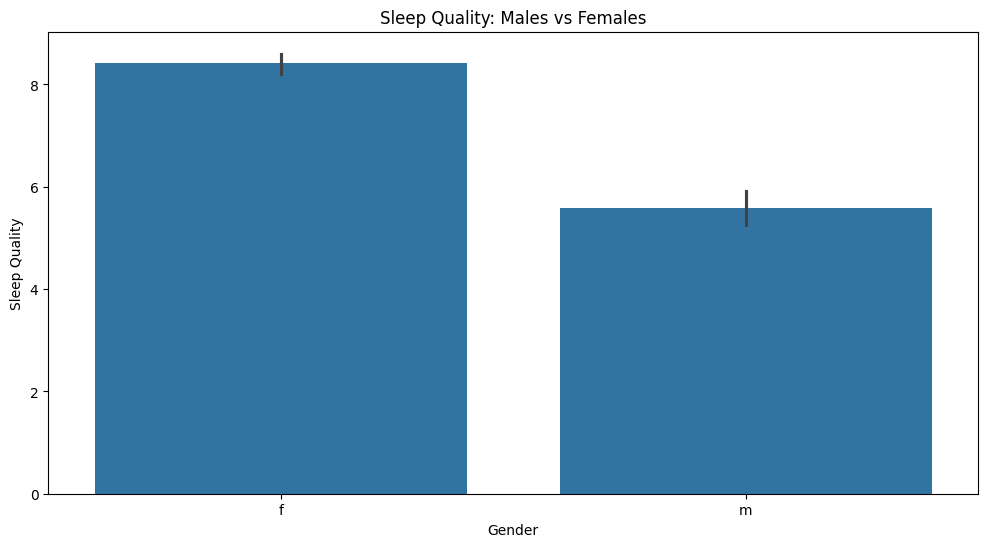

In [76]:
plt.figure(figsize=(12,6))
sns.barplot(x='Gender', y='Sleep Quality', data=df)
plt.title('Sleep Quality: Males vs Females')
plt.show()

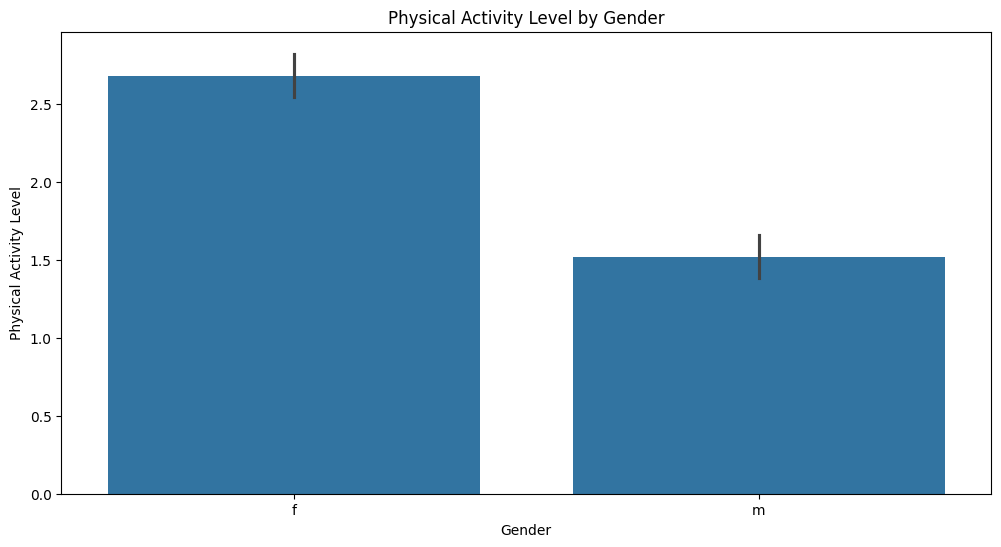

In [77]:
df = pd.read_csv(DATA_PATH, encoding='utf-8')
custom_codes = {'low': 1, 'medium': 2, 'high': 3}
df['Physical Activity Level'] = df['Physical Activity Level'].map(custom_codes)

plt.figure(figsize=(12,6))
sns.barplot(x='Gender', y='Physical Activity Level', data=df)
plt.title('Physical Activity Level by Gender')
plt.show()

In simple terms, the T-test and P-value help us compare two groups (like males and females) to see if their average values (like sleep quality or physical activity level) are significantly different from each other.

What is a T-test? A T-test compares the means (average values) of two groups to determine if the difference between them is statistically significant. In your case, you're comparing:

Sleep quality of males vs. females Physical activity level of males vs. females What does the T-statistic mean? The T-statistic measures how different the means of two groups are, relative to the variation in their data. A high absolute value (like -14.32 or -10.98) means there is a large difference between the groups, while a value closer to 0 would mean there's little to no difference.
A negative T-statistic means the first group (males) has a lower mean than the second group (females). A positive T-statistic would mean the opposite (males have a higher mean). What is the P-value? The P-value tells you how likely it is that the difference you observed between the two groups is due to random chance.

If the P-value is very small (like 0.0000), it suggests that the difference between the groups is statistically significant and not just random. In other words, there's a strong likelihood that the groups are truly different. A large P-value (greater than 0.05) would mean the difference is likely due to random variation, so we wouldn't consider the difference meaningful. Why T-test and P-value for Sleep Quality and Physical Activity? You're using the T-test and P-value to answer these questions:
For Sleep Quality: "Is there a significant difference between how males and females rate their sleep quality?" The T-statistic of -14.32 and P-value of 0.0000 show that males and females have a statistically significant difference in their sleep quality, with males having a lower average sleep quality than females. For Physical Activity Level: "Is there a significant difference in the physical activity levels between males and females?" The T-statistic of -10.98 and P-value of 0.0000 again indicate a significant difference, with males having lower physical activity levels compared to females. Summary You found the T-values and P-values to compare the average sleep quality and physical activity levels between males and females. Since both P-values are close to 0, it means the differences you found are statistically significant, meaning males and females are likely to have different sleep quality and physical activity levels in the dataset.


In [78]:
sleep_quality_males = df[df['Gender'] == 'm']['Sleep Quality']
sleep_quality_females = df[df['Gender'] == 'f']['Sleep Quality']
t_sleep_quality, p_sleep_quality = stats.ttest_ind(sleep_quality_males, sleep_quality_females, nan_policy='omit')

physical_activity_males = df[df['Gender'] == 'm']['Physical Activity Level']
physical_activity_females = df[df['Gender'] == 'f']['Physical Activity Level']
t_physical_activity, p_physical_activity = stats.ttest_ind(physical_activity_males, physical_activity_females, nan_policy='omit')
print(f"T-test Sleep Quality: t={t_sleep_quality:.2f}, p={p_sleep_quality:.4f}")
print(f"T-test Physical Activity: t={t_physical_activity:.2f}, p={p_physical_activity:.4f}")


T-test Sleep Quality: t=-14.32, p=0.0000
T-test Physical Activity: t=-10.98, p=0.0000


In [79]:
def sleep_duration_hours_helper_function(str_time):
    h = int(str_time.split(':')[0])
    m = int(str_time.split(':')[1])
    return h + m/60

df['Bedtime'] = df['Bedtime'].apply(sleep_duration_hours_helper_function)
df['Wake-up Time'] = df['Wake-up Time'].apply(sleep_duration_hours_helper_function)

df['Sleep Duration Hours'] = (df['Wake-up Time'] - df['Bedtime']) % 24
print(df[['Bedtime', 'Wake-up Time', 'Sleep Duration Hours']].head())
df.head()


   Bedtime  Wake-up Time  Sleep Duration Hours
0    23.00          6.50                   7.5
1     0.50          7.00                   6.5
2    22.75          6.75                   8.0
3     1.00          6.50                   5.5
4    23.50          7.00                   7.5


,User ID,Age,Gender,Sleep Quality,Bedtime,Wake-up Time,Daily Steps,Calories Burned,Physical Activity Level,Dietary Habits,Sleep Disorders,Medication Usage,Sleep Duration Hours
0,1,25,f,8,23.00,6.50,8000,2500,2,healthy,no,no,7.5
1,2,34,m,7,0.50,7.00,5000,2200,1,unhealthy,yes,yes,6.5
2,3,29,f,9,22.75,6.75,9000,2700,3,healthy,no,no,8.0
3,4,41,m,5,1.00,6.50,4000,2100,1,unhealthy,yes,no,5.5
4,5,22,f,8,23.50,7.00,10000,2800,3,medium,no,no,7.5


In [80]:
df['Sleep Duration Hours'] = (df['Wake-up Time'] - df['Bedtime']) % 24
df.head()

,User ID,Age,Gender,Sleep Quality,Bedtime,Wake-up Time,Daily Steps,Calories Burned,Physical Activity Level,Dietary Habits,Sleep Disorders,Medication Usage,Sleep Duration Hours
0,1,25,f,8,23.00,6.50,8000,2500,2,healthy,no,no,7.5
1,2,34,m,7,0.50,7.00,5000,2200,1,unhealthy,yes,yes,6.5
2,3,29,f,9,22.75,6.75,9000,2700,3,healthy,no,no,8.0
3,4,41,m,5,1.00,6.50,4000,2100,1,unhealthy,yes,no,5.5
4,5,22,f,8,23.50,7.00,10000,2800,3,medium,no,no,7.5


In [81]:
gender_summary = df.groupby('Gender')[['Sleep Quality', 'Physical Activity Level', 'Calories Burned', 'Sleep Duration Hours']].mean().round(2)
print("\n=== Average Metrics by Gender ===")
print(gender_summary)


=== Average Metrics by Gender ===
        Sleep Quality  Physical Activity Level  Calories Burned  \
Gender                                                            
f                8.42                     2.68           2654.0   
m                5.58                     1.52           2188.0   

        Sleep Duration Hours  
Gender                        
f                       7.89  
m                       6.10  


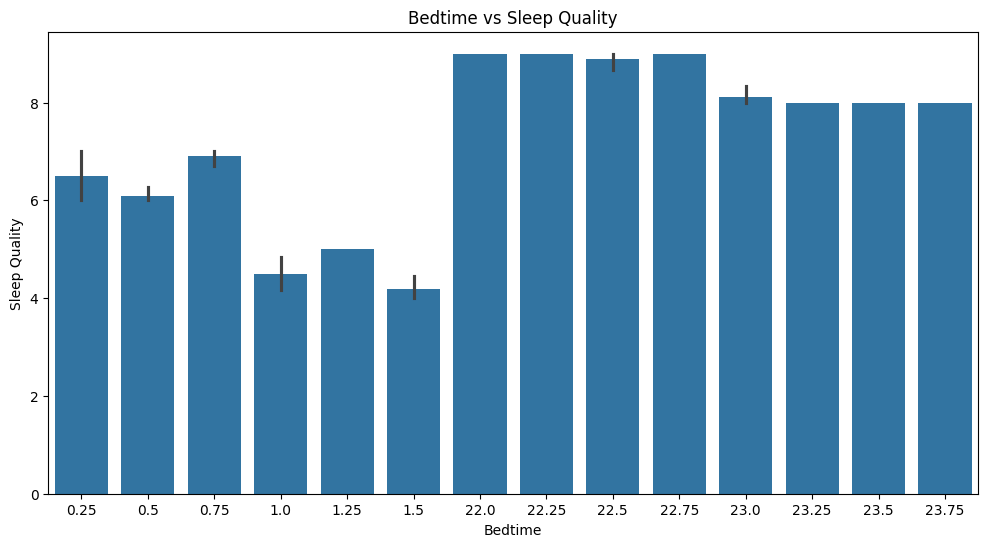

In [83]:
plt.figure(figsize=(12,6))
sns.barplot(x='Bedtime', y='Sleep Quality', data=df)
plt.title("Bedtime vs Sleep Quality")
plt.show()

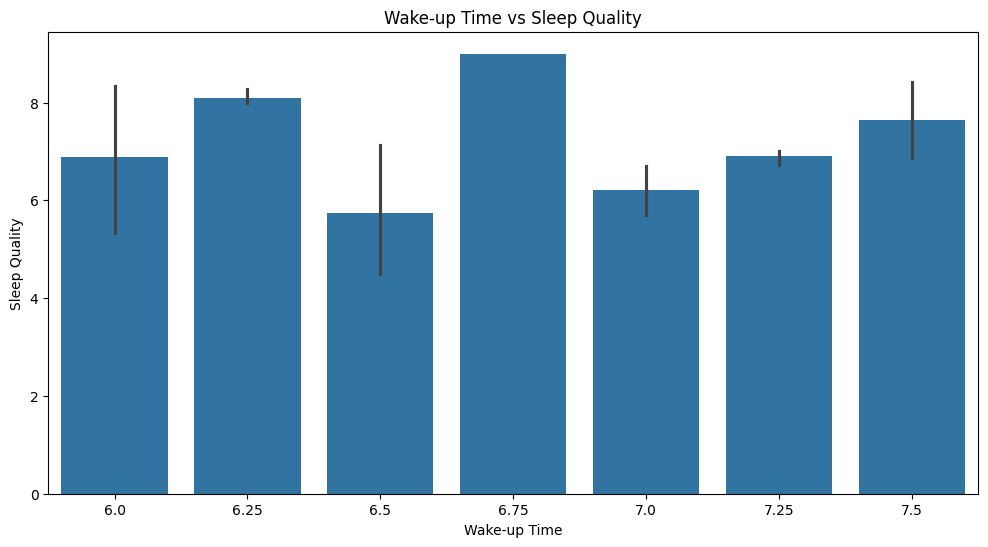

In [84]:
plt.figure(figsize=(12,6))
sns.barplot(x='Wake-up Time', y='Sleep Quality', data=df)
plt.title("Wake-up Time vs Sleep Quality")
plt.show()

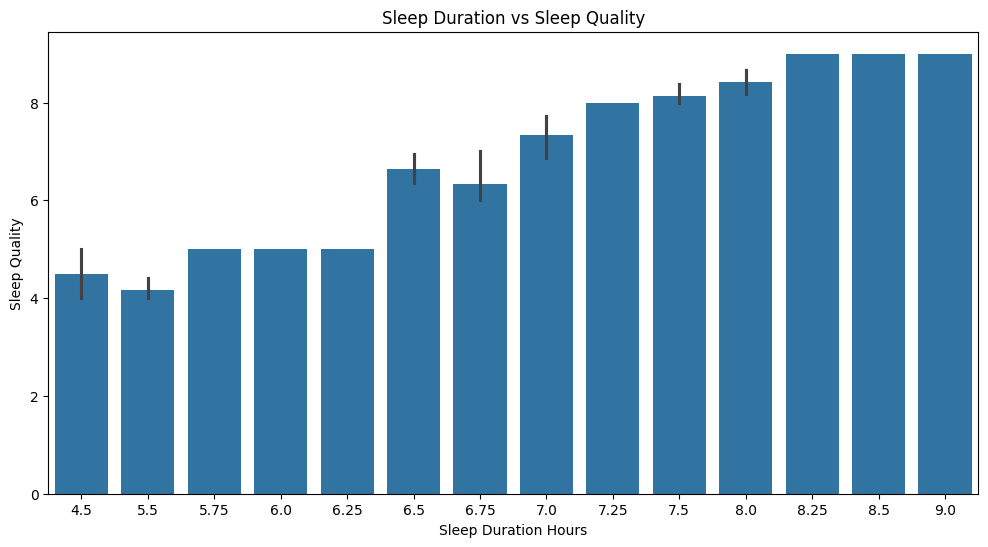

In [85]:
plt.figure(figsize=(12,6))
sns.barplot(x='Sleep Duration Hours', y='Sleep Quality', data=df)
plt.title("Sleep Duration vs Sleep Quality")
plt.show()

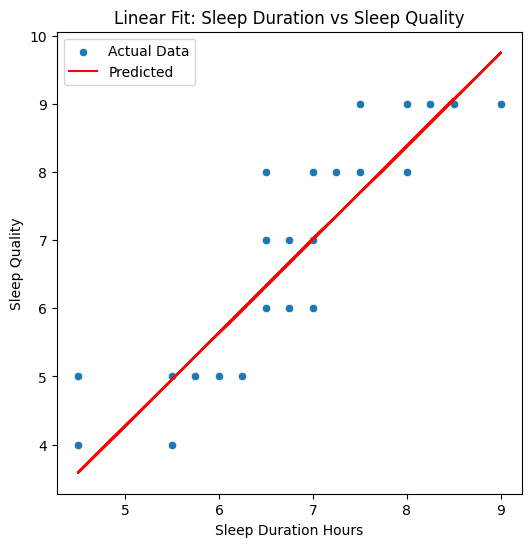

R² Score: 0.8443929044393099


In [86]:
X = df[['Sleep Duration Hours']]
Y = df['Sleep Quality']
model = LinearRegression()
model.fit(X, Y)
plt.figure(figsize=(6,6))
sns.scatterplot(x='Sleep Duration Hours', y='Sleep Quality', data=df, label='Actual Data')
plt.plot(X, model.predict(X), color='red', label='Predicted')
plt.legend()
plt.title("Linear Fit: Sleep Duration vs Sleep Quality")
plt.show()
print("R² Score:", r2_score(Y, model.predict(X)))

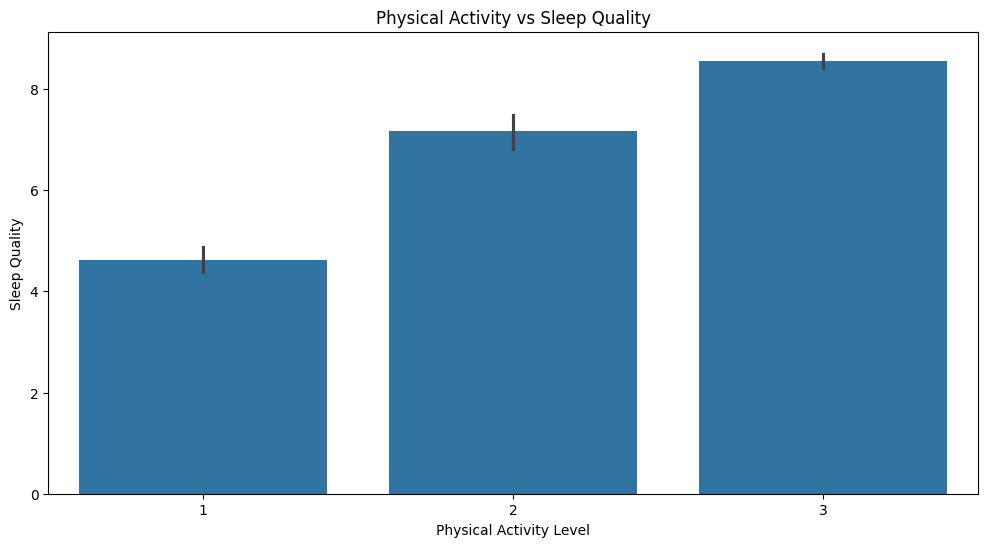

In [87]:
plt.figure(figsize=(12,6))
sns.barplot(x='Physical Activity Level', y='Sleep Quality', data=df)
plt.title('Physical Activity vs Sleep Quality')
plt.show()

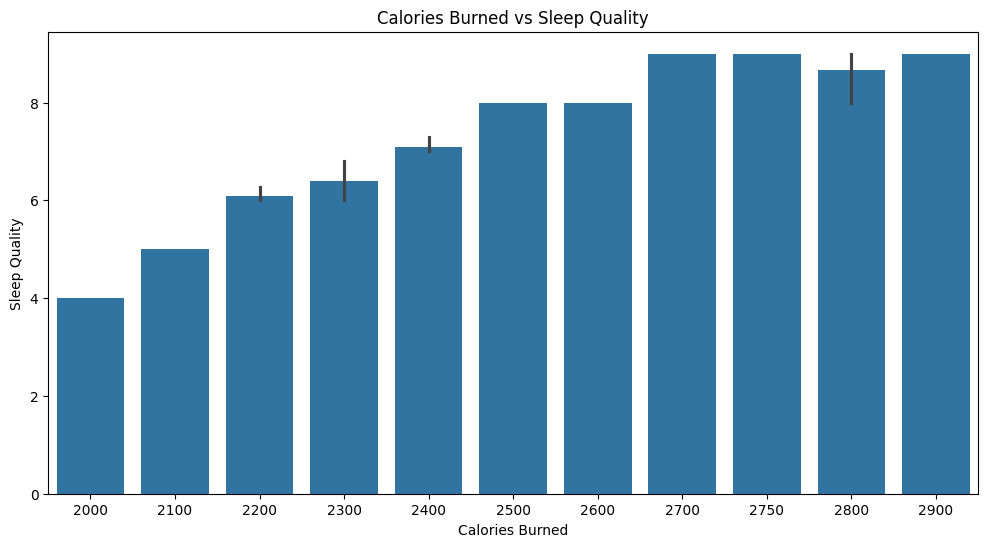

In [88]:
plt.figure(figsize=(12,6))
sns.barplot(x='Calories Burned', y='Sleep Quality', data=df)
plt.title('Calories Burned vs Sleep Quality')
plt.show()

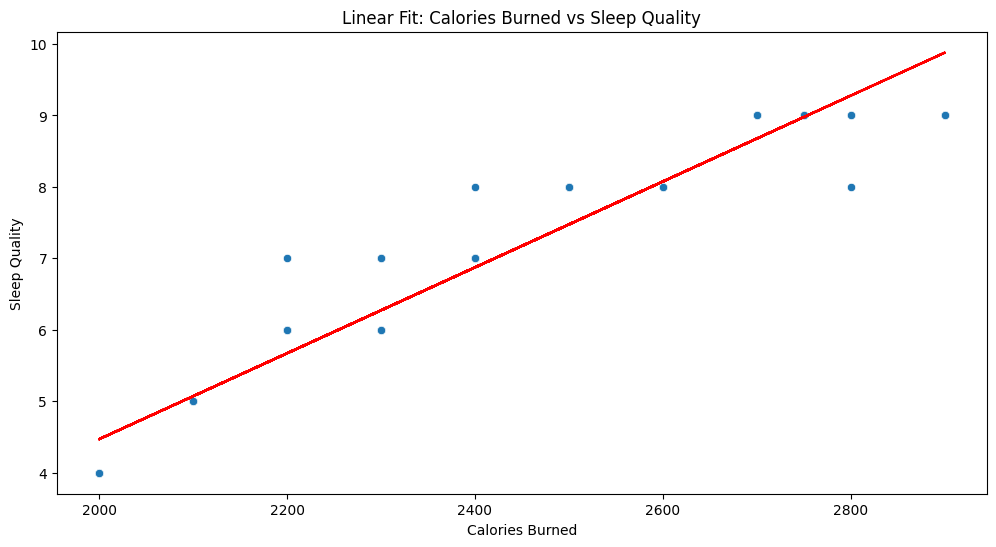

R² Score: 0.9478131260919267


In [89]:
model = LinearRegression()
X = df[['Calories Burned']]
Y = df['Sleep Quality']
model.fit(X, Y)
plt.figure(figsize=(12,6))
sns.scatterplot(x='Calories Burned', y='Sleep Quality', data=df)
plt.plot(X, model.predict(X), color='red')
plt.title("Linear Fit: Calories Burned vs Sleep Quality")
plt.show()
print("R² Score:", r2_score(Y, model.predict(X)))

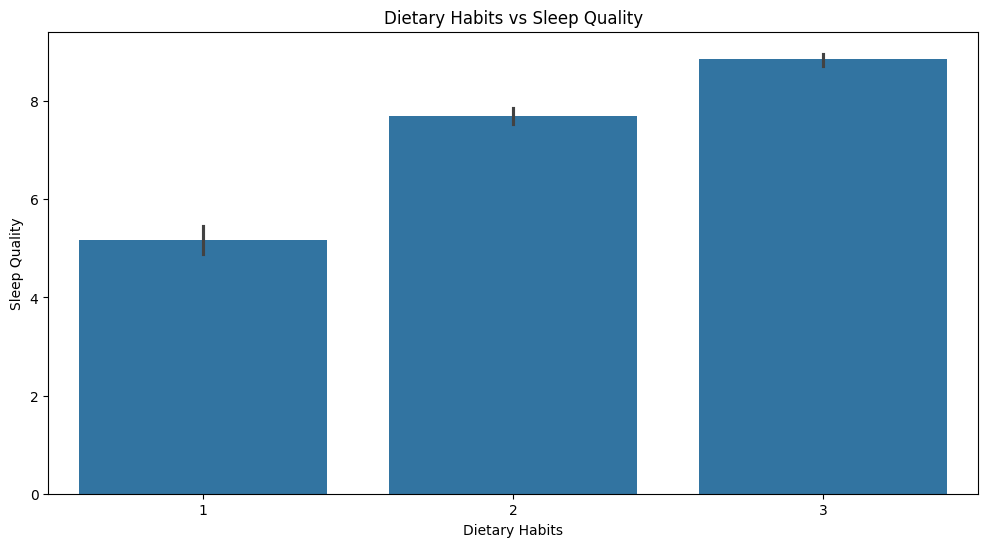

In [90]:
custom_codes = {'unhealthy': 1, 'medium': 2, 'healthy': 3}
df['Dietary Habits'] = df['Dietary Habits'].map(custom_codes)

plt.figure(figsize=(12,6))
sns.barplot(x='Dietary Habits', y='Sleep Quality', data=df)
plt.title('Dietary Habits vs Sleep Quality')
plt.show()

In [91]:
df['Sleep Disorders'].head()


0     no
1    yes
2     no
3    yes
4     no
Name: Sleep Disorders, dtype: object

In [92]:
sleep_disorder_sleep_quality_summary = df.groupby('Sleep Disorders').agg({
    'Sleep Quality': ['mean', 'std'],
    'Physical Activity Level': lambda x: x.value_counts().to_dict()
})
print(sleep_disorder_sleep_quality_summary)

                Sleep Quality           Physical Activity Level
                         mean       std                <lambda>
Sleep Disorders                                                
no                   7.837838  1.085736          {2: 38, 3: 36}
yes                  4.615385  0.697247                 {1: 26}


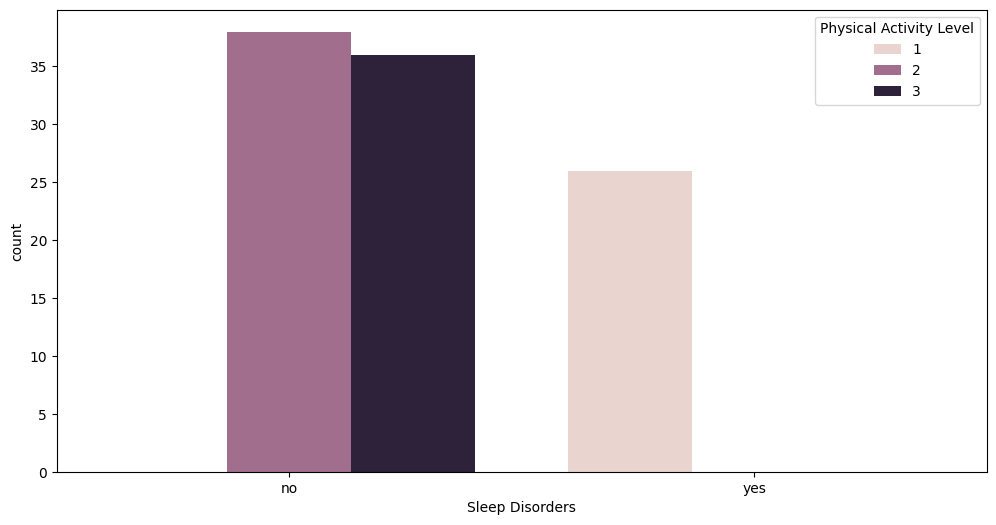

In [93]:
plt.figure(figsize = (12, 6))
sns.countplot(x = 'Sleep Disorders', hue = 'Physical Activity Level', data = df)
plt.show()

Text(0, 0.5, 'Sleep Quality')

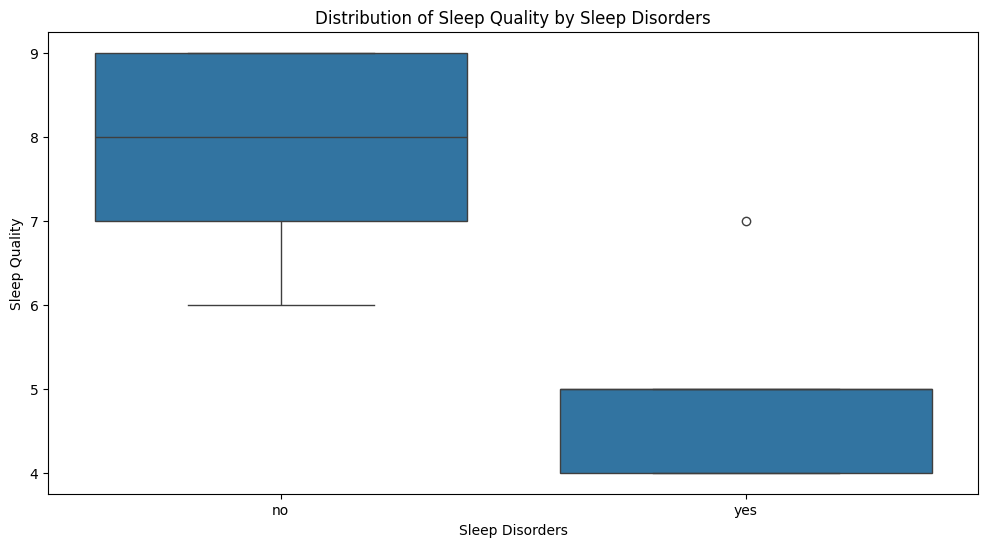

In [94]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Sleep Disorders', y='Sleep Quality', data=df)
plt.title('Distribution of Sleep Quality by Sleep Disorders')
plt.xlabel('Sleep Disorders')
plt.ylabel('Sleep Quality')

In [95]:
yes_sleep_disorder_quality = df[df['Sleep Disorders'] == 'yes']['Sleep Quality']
no_sleep_disorder_quality =  df[df['Sleep Disorders'] == 'no']['Sleep Quality']

t_sleep_disorder_quality, p_sleep_disorder_quality = stats.ttest_ind(yes_sleep_disorder_quality, no_sleep_disorder_quality, nan_policy='omit')
print(f"t-sleep-disorder-quality : {t_sleep_disorder_quality:.2f}")
print(f"p-sleep-disorder-quality : {p_sleep_disorder_quality:.2f}")

t-sleep-disorder-quality : -14.12
p-sleep-disorder-quality : 0.00


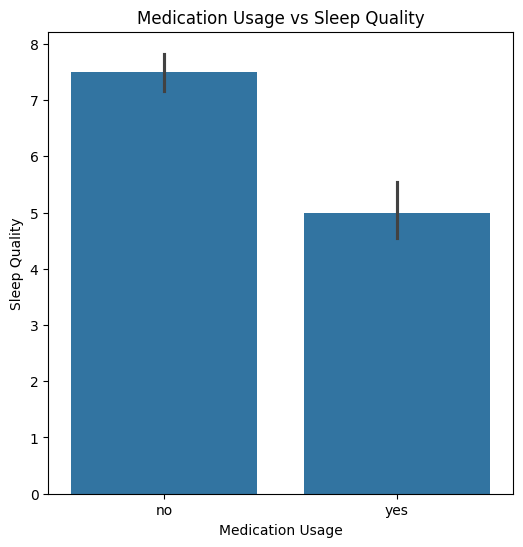

T-test Medication: t=-8.08, p=0.0000


In [96]:
plt.figure(figsize=(6,6))
sns.barplot(x='Medication Usage', y='Sleep Quality', data=df)
plt.title('Medication Usage vs Sleep Quality')
plt.show()

med_yes = df[df['Medication Usage'] == 'yes']['Sleep Quality']
med_no = df[df['Medication Usage'] == 'no']['Sleep Quality']
t_stat, p_val = stats.ttest_ind(med_yes, med_no, equal_var=False)
print(f"T-test Medication: t={t_stat:.2f}, p={p_val:.4f}")


=== Correlation with Sleep Quality ===
Sleep Quality              1.000000
Daily Steps                0.976277
Calories Burned            0.973557
Sleep Duration Hours       0.918909
Dietary Habits             0.902498
Physical Activity Level    0.875203
Bedtime                    0.853312
User ID                   -0.014248
Wake-up Time              -0.048526
Age                       -0.848356
Name: Sleep Quality, dtype: float64


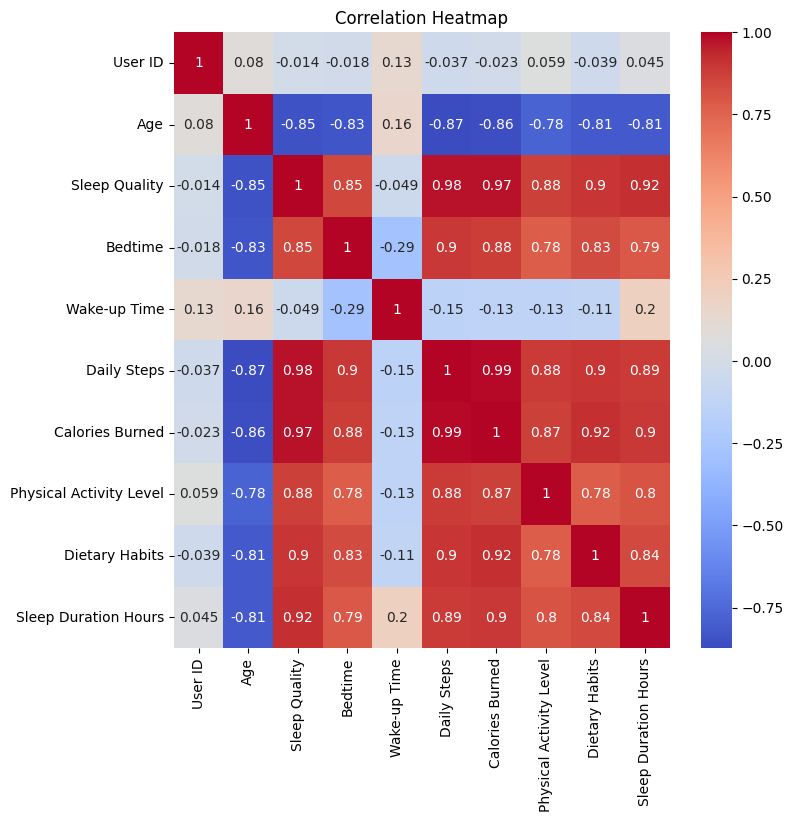

In [97]:
df_numeric = df.select_dtypes(include=['number'])
corr = df_numeric.corr()
print("\n=== Correlation with Sleep Quality ===")
print(corr['Sleep Quality'].sort_values(ascending=False))

plt.figure(figsize=(8,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

C:\Users\Windows\AppData\Local\Temp\ipykernel_14260\572868921.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_corr.values, y=top_corr.index, palette='viridis')


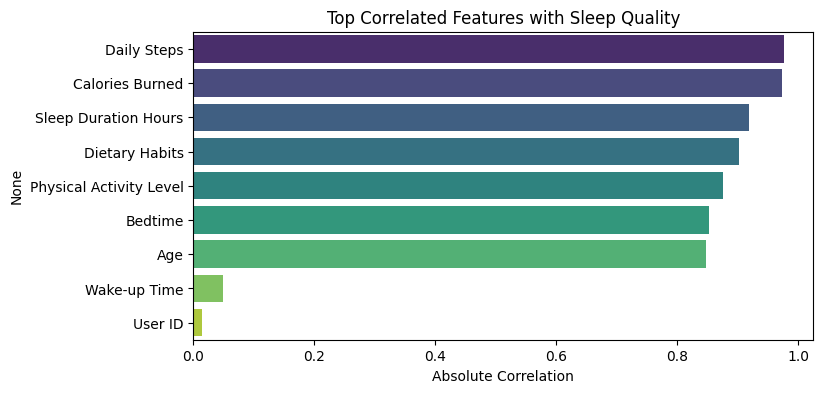

In [98]:

top_corr = corr['Sleep Quality'].abs().sort_values(ascending=False)[1:10]  # exclude self-corr
plt.figure(figsize=(8,4))
sns.barplot(x=top_corr.values, y=top_corr.index, palette='viridis')
plt.title("Top Correlated Features with Sleep Quality")
plt.xlabel("Absolute Correlation")
plt.show()